# Clasificación de compuertas lógicas dibujadas a mano

**PC2 · Computación Gráfica · UNI**

**Problema:** digitalizar circuitos lógicos dibujados a mano. Como primer paso, una red neuronal debe reconocer qué compuerta se dibujó.

**Clases (6):** AND, OR, NOT, NAND, NOR, XOR.

**Datos:** dibujos recolectados por el equipo con la app web del repositorio (lienzo de 256×256). Cada PNG está en una carpeta con el nombre de su clase y el trazo va en el canal alfa.

**Contenido del notebook**
1. Carga de datos
2. Preprocesamiento
3. Exploración del dataset
4. División en entrenamiento, validación y prueba
5. Modelo base: perceptrón multicapa (MLP)
6. Red neuronal convolucional (CNN)
7. Métricas: accuracy, precisión, recall, F1 y matriz de confusión
8. Análisis de errores y parejas difíciles (AND/NAND, OR/NOR, OR/XOR)
9. Experimento: ¿cuánto importa la resolución de la imagen?
10. Generalización a personas que no participaron en el entrenamiento
11. Global Average Pooling y Class Activation Maps (CAM)
12. Conclusiones

## 1. Carga de datos

El dataset final está en el repositorio como `dataset.zip`: 3000 dibujos, 500 por compuerta, descargados de la app desplegada. Si el archivo no está en la carpeta actual (por ejemplo, al abrir el notebook en Colab), se descarga del repositorio.

In [1]:
import os, io, json, zipfile, urllib.request, collections
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

URL_DATASET = "https://github.com/Faalvial/compuertas_logicas/raw/main/dataset.zip"
RUTA_ZIP = "dataset.zip"
CARPETA = "dataset"
CLASES = ["AND", "OR", "NOT", "NAND", "NOR", "XOR"]

if not os.path.exists(RUTA_ZIP):
    print("Descargando", URL_DATASET)
    urllib.request.urlretrieve(URL_DATASET, RUTA_ZIP)

with zipfile.ZipFile(RUTA_ZIP) as zf:
    zf.extractall(CARPETA)
print("Dataset extraído en", CARPETA)

Dataset extraído en dataset


## 2. Preprocesamiento

Cada dibujo pasa por estos pasos:
1. **Canal alfa:** el lienzo es transparente y el trazo es opaco, así que el canal alfa ya es la imagen en escala de grises (0 = fondo, 255 = tinta).
2. **Recorte:** se recorta al rectángulo que contiene la tinta, con un margen. Así no importa en qué parte del lienzo ni de qué tamaño dibujó cada persona.
3. **Cuadrado:** se rellena con fondo para que quede cuadrado sin deformar la compuerta.
4. **Redimensionar:** a `TAM × TAM` píxeles (64 por defecto) y normalizar a valores entre 0 y 1.

Los recortes cuadrados se guardan a resolución completa para poder generar luego versiones de 16, 28 o 64 píxeles en el experimento de resolución.

In [2]:
TAM = 64
MARGEN = 0.08

def recortar_cuadrado(ruta, margen=MARGEN):
    alfa = Image.open(ruta).convert("RGBA").getchannel("A")
    caja = alfa.getbbox()                     # rectángulo con tinta
    if caja is None:
        return None
    x0, y0, x1, y1 = caja
    lado = int(max(x1 - x0, y1 - y0) * (1 + 2 * margen))
    cuadrado = Image.new("L", (lado, lado), 0)
    cuadrado.paste(alfa.crop(caja), ((lado - (x1 - x0)) // 2, (lado - (y1 - y0)) // 2))
    return cuadrado

def a_matriz(recortes, tam):
    return np.stack([np.asarray(r.resize((tam, tam), Image.Resampling.LANCZOS), dtype=np.float32) / 255.0
                     for r in recortes])

recortes, etiquetas, autores, archivos = [], [], [], []
for i, clase in enumerate(CLASES):
    carpeta = os.path.join(CARPETA, clase)
    for nombre in sorted(os.listdir(carpeta)):
        if not nombre.endswith(".png"):
            continue
        r = recortar_cuadrado(os.path.join(carpeta, nombre))
        if r is None:
            continue
        recortes.append(r)
        etiquetas.append(i)
        partes = nombre.split("_")
        autores.append(partes[1] if len(partes) >= 3 else "anonimo")
        archivos.append(f"{clase}/{nombre}")

y = np.array(etiquetas)
autores = np.array(autores)
X = a_matriz(recortes, TAM)
print("Imágenes:", X.shape, " Etiquetas:", y.shape)

Imágenes: (3000, 64, 64)  Etiquetas: (3000,)


## 3. Exploración del dataset

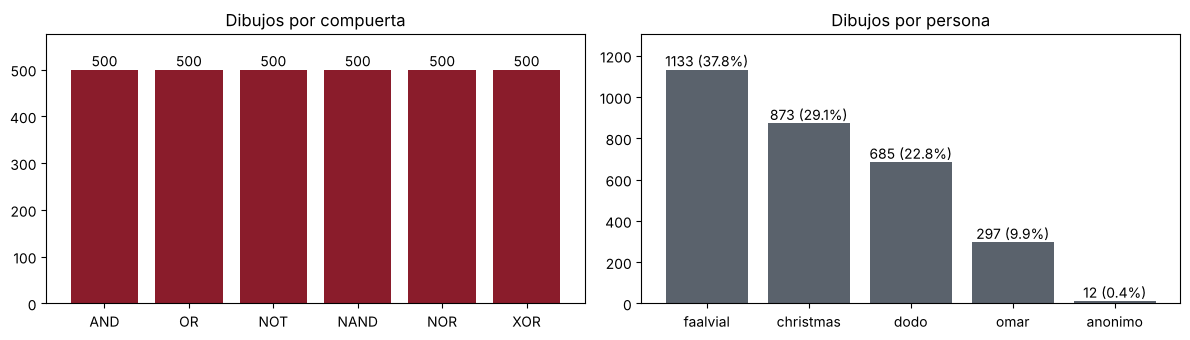

{'AND': 500, 'OR': 500, 'NOT': 500, 'NAND': 500, 'NOR': 500, 'XOR': 500}  total: 3000


In [3]:
conteo = np.bincount(y, minlength=len(CLASES))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(CLASES, conteo, color="#8a1c2b")
ax[0].set_title("Dibujos por compuerta")
for i, n in enumerate(conteo):
    ax[0].text(i, n, str(n), ha="center", va="bottom")
ax[0].set_ylim(0, conteo.max() * 1.15)
por_autor = collections.Counter(autores)
nombres = [a for a, _ in por_autor.most_common()]
ax[1].bar(nombres, [por_autor[a] for a in nombres], color="#5a626c")
ax[1].set_title("Dibujos por persona")
for i, a in enumerate(nombres):
    ax[1].text(i, por_autor[a], f"{por_autor[a]} ({por_autor[a] / len(y):.1%})", ha="center", va="bottom")
ax[1].set_ylim(0, max(por_autor.values()) * 1.15)
plt.tight_layout(); plt.show()
print(dict(zip(CLASES, conteo.tolist())), " total:", conteo.sum())

**Aporte de cada persona** por compuerta. `anonimo` son los dibujos enviados sin nombre.

In [4]:
print(f"{'Persona':<12}" + "".join(f"{c:>6}" for c in CLASES) + f"{'Total':>7}{'Aporte':>8}")
for a in nombres:
    fila = [int(((autores == a) & (y == i)).sum()) for i in range(len(CLASES))]
    print(f"{a:<12}" + "".join(f"{n:>6}" for n in fila) + f"{sum(fila):>7}{sum(fila) / len(y):>8.1%}")
print(f"{'Total':<12}" + "".join(f"{n:>6}" for n in conteo) + f"{len(y):>7}{1:>8.0%}")

Persona        AND    OR   NOT  NAND   NOR   XOR  Total  Aporte
faalvial       185   188   188   190   190   192   1133   37.8%
christmas      149   144   142   147   152   139    873   29.1%
dodo           116   120   116   110   108   115    685   22.8%
omar            50    46    51    50    48    52    297    9.9%
anonimo          0     2     3     3     2     2     12    0.4%
Total          500   500   500   500   500   500   3000    100%


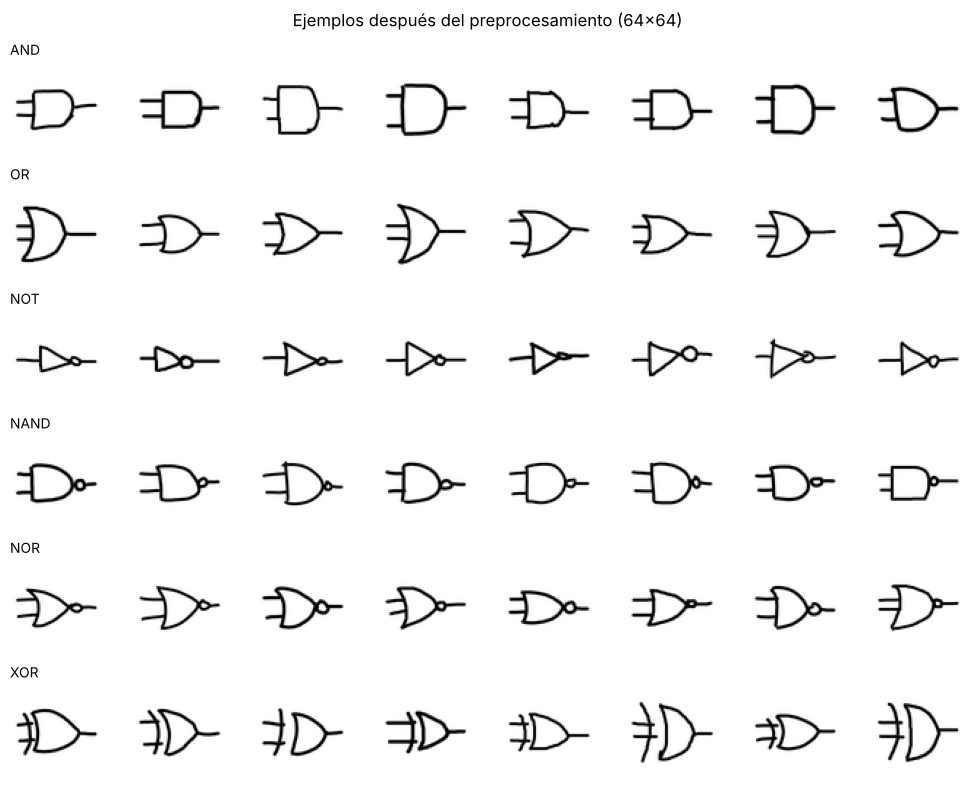

In [5]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(CLASES), 8, figsize=(10, 8))
for i, clase in enumerate(CLASES):
    idx = rng.choice(np.where(y == i)[0], size=min(8, (y == i).sum()), replace=False)
    for j in range(8):
        a = axes[i, j]; a.axis("off")
        if j < len(idx):
            a.imshow(X[idx[j]], cmap="gray_r")
    axes[i, 0].set_title(clase, loc="left", fontsize=10)
plt.suptitle(f"Ejemplos después del preprocesamiento ({TAM}×{TAM})"); plt.tight_layout(); plt.show()

La **imagen promedio** de cada clase muestra qué tan consistentes son los dibujos. En NAND y NOR debería verse el círculo de la salida; en XOR, la curva extra.

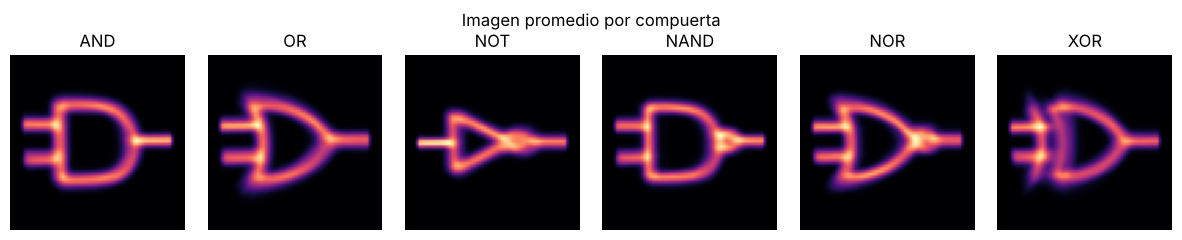

In [6]:
fig, axes = plt.subplots(1, len(CLASES), figsize=(12, 2.4))
for i, clase in enumerate(CLASES):
    axes[i].imshow(X[y == i].mean(axis=0), cmap="magma"); axes[i].set_title(clase); axes[i].axis("off")
plt.suptitle("Imagen promedio por compuerta"); plt.tight_layout(); plt.show()

## 4. División en entrenamiento, validación y prueba

- **Entrenamiento (70%)**: la red aprende con estos datos.
- **Validación (15%)**: sirve para decidir cuándo dejar de entrenar.
- **Prueba (15%)**: solo se usa al final para medir el rendimiento real.

La división es **estratificada** (cada conjunto tiene la misma proporción de cada compuerta) y se guardan los índices para reutilizar exactamente la misma división en todos los experimentos.

In [7]:
from sklearn.model_selection import train_test_split
import logging
import keras
from keras import layers

logging.getLogger("tensorflow").setLevel(logging.ERROR)  # oculta avisos internos de TensorFlow

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

indices = np.arange(len(y))
idx_train, idx_tmp = train_test_split(indices, test_size=0.30, stratify=y, random_state=SEMILLA)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEMILLA)

def separar(Xs):
    Xs = Xs[..., None]  # canal de color
    return Xs[idx_train], Xs[idx_val], Xs[idx_test]

X_train, X_val, X_test = separar(X)
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]
print("Entrenamiento:", X_train.shape, " Validación:", X_val.shape, " Prueba:", X_test.shape)

Entrenamiento: (2100, 64, 64, 1)  Validación: (450, 64, 64, 1)  Prueba: (450, 64, 64, 1)


## 5. Modelo base: perceptrón multicapa (MLP)

Primero una red densa simple, que ve la imagen como un vector de píxeles sin estructura espacial. Sirve como punto de comparación para la CNN.

In [8]:
EPOCAS = 60

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4)]

def crear_mlp(tam):
    return keras.Sequential([
        keras.Input((tam, tam, 1)),
        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(len(CLASES), activation="softmax"),
    ], name="MLP")

mlp = crear_mlp(TAM)
mlp.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mlp.summary()
hist_mlp = mlp.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCAS,
                   batch_size=64, callbacks=callbacks(), verbose=2)

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,082,502 (4.13 MB)

 Trainable params: 1,082,502 (4.13 MB)

 Non-trainable params: 0 (0.00 B)

...

33/33 - 0s - 10ms/step - accuracy: 0.9995 - loss: 0.0021 - val_accuracy: 0.9956 - val_loss: 0.0188 - learning_rate: 2.5000e-04


Epoch 26/60


33/33 - 0s - 9ms/step - accuracy: 0.9995 - loss: 0.0027 - val_accuracy: 0.9956 - val_loss: 0.0173 - learning_rate: 2.5000e-04


Epoch 27/60


33/33 - 0s - 11ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 0.9978 - val_loss: 0.0169 - learning_rate: 2.5000e-04


## 6. Red neuronal convolucional (CNN)

La CNN aprende filtros que detectan bordes, curvas y círculos, y luego los combina. Eso la hace adecuada para distinguir detalles como el círculo de NAND o la curva extra de XOR.

**Aumento de datos:** durante el entrenamiento cada imagen se rota (±10°), se desplaza y se acerca o aleja un poco al azar, para simular la variación natural entre personas. **No** se aplica volteo horizontal: una compuerta volteada tendría la salida a la izquierda, que no es un dibujo válido.

**Arquitectura:** tres bloques de convolución + max pooling (32, 64 y 128 filtros), seguidos de una capa densa con dropout para reducir el sobreajuste.

In [9]:
def crear_aumento():
    return keras.Sequential([
        layers.RandomRotation(0.03, fill_mode="constant"),
        layers.RandomTranslation(0.08, 0.08, fill_mode="constant"),
        layers.RandomZoom(0.1, fill_mode="constant"),
    ], name="aumento_de_datos")

def crear_cnn(tam):
    return keras.Sequential([
        keras.Input((tam, tam, 1)),
        crear_aumento(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(0.4),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(len(CLASES), activation="softmax"),
    ], name="CNN")

cnn = crear_cnn(TAM)
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()
hist_cnn = cnn.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCAS,
                   batch_size=64, callbacks=callbacks(), verbose=2)

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_datos (Sequential)   │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,188,326 (4.53 MB)

 Trainable params: 1,188,326 (4.53 MB)

 Non-trainable params: 0 (0.00 B)

...

33/33 - 6s - 179ms/step - accuracy: 0.9938 - loss: 0.0235 - val_accuracy: 0.9978 - val_loss: 0.0071 - learning_rate: 5.0000e-04


Epoch 18/60


33/33 - 10s - 313ms/step - accuracy: 0.9952 - loss: 0.0161 - val_accuracy: 0.9978 - val_loss: 0.0091 - learning_rate: 5.0000e-04


Epoch 19/60


33/33 - 6s - 176ms/step - accuracy: 0.9967 - loss: 0.0109 - val_accuracy: 0.9978 - val_loss: 0.0055 - learning_rate: 5.0000e-04


### Curvas de entrenamiento

Si la pérdida de validación sube mientras la de entrenamiento baja, la red está memorizando (sobreajuste). `EarlyStopping` detiene el entrenamiento en ese punto y recupera los mejores pesos.

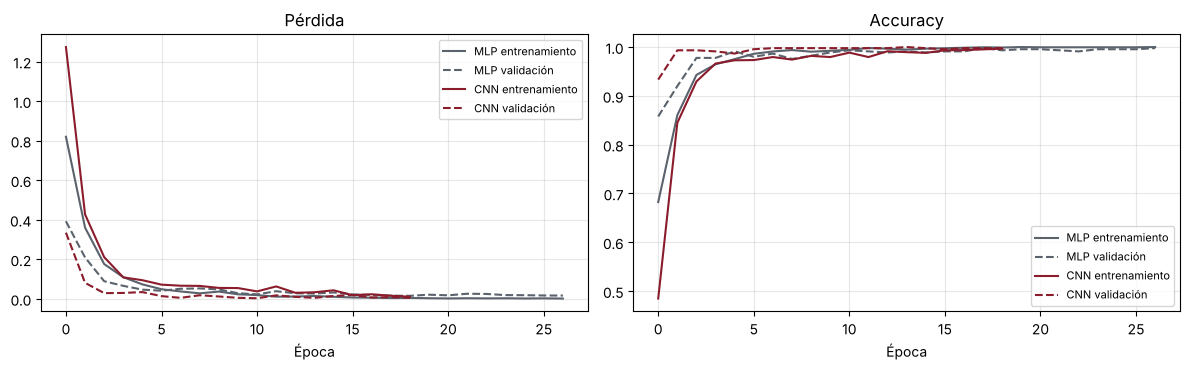

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for h, nombre, color in [(hist_mlp, "MLP", "#5a626c"), (hist_cnn, "CNN", "#8a1c2b")]:
    axes[0].plot(h.history["loss"], color=color, label=f"{nombre} entrenamiento")
    axes[0].plot(h.history["val_loss"], color=color, ls="--", label=f"{nombre} validación")
    axes[1].plot(h.history["accuracy"], color=color, label=f"{nombre} entrenamiento")
    axes[1].plot(h.history["val_accuracy"], color=color, ls="--", label=f"{nombre} validación")
axes[0].set_title("Pérdida"); axes[1].set_title("Accuracy")
for a in axes:
    a.set_xlabel("Época"); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Métricas en el conjunto de prueba

- **Accuracy:** porcentaje de dibujos clasificados correctamente.
- **Precisión** de una clase: de los dibujos que la red dijo que eran NAND, cuántos lo eran de verdad.
- **Recall** de una clase: de los NAND reales, cuántos encontró la red.
- **F1:** media armónica de precisión y recall.
- **Matriz de confusión:** fila = compuerta real, columna = compuerta predicha. Lo que está fuera de la diagonal son errores.

In [11]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay

def evaluar(modelo, Xt, yt):
    prob = modelo.predict(Xt, verbose=0)
    pred = prob.argmax(axis=1)
    return pred, prob

pred_mlp, _ = evaluar(mlp, X_test, y_test)
pred_cnn, prob_cnn = evaluar(cnn, X_test, y_test)

for nombre, pred in [("MLP", pred_mlp), ("CNN", pred_cnn)]:
    print(f"===== {nombre} =====")
    print(classification_report(y_test, pred, target_names=CLASES, digits=3))

===== MLP =====
              precision    recall  f1-score   support

         AND      0.987     0.987     0.987        75
          OR      0.986     0.960     0.973        75
         NOT      1.000     1.000     1.000        75
        NAND      1.000     0.973     0.986        75
         NOR      0.987     1.000     0.993        75
         XOR      0.962     1.000     0.980        75

    accuracy                          0.987       450
   macro avg      0.987     0.987     0.987       450
weighted avg      0.987     0.987     0.987       450

===== CNN =====
              precision    recall  f1-score   support

         AND      1.000     0.987     0.993        75
          OR      0.987     1.000     0.993        75
         NOT      1.000     1.000     1.000        75
        NAND      1.000     0.987     0.993        75
         NOR      0.987     1.000     0.993        75
         XOR      1.000     1.000     1.000        75

    accuracy                          0.996  

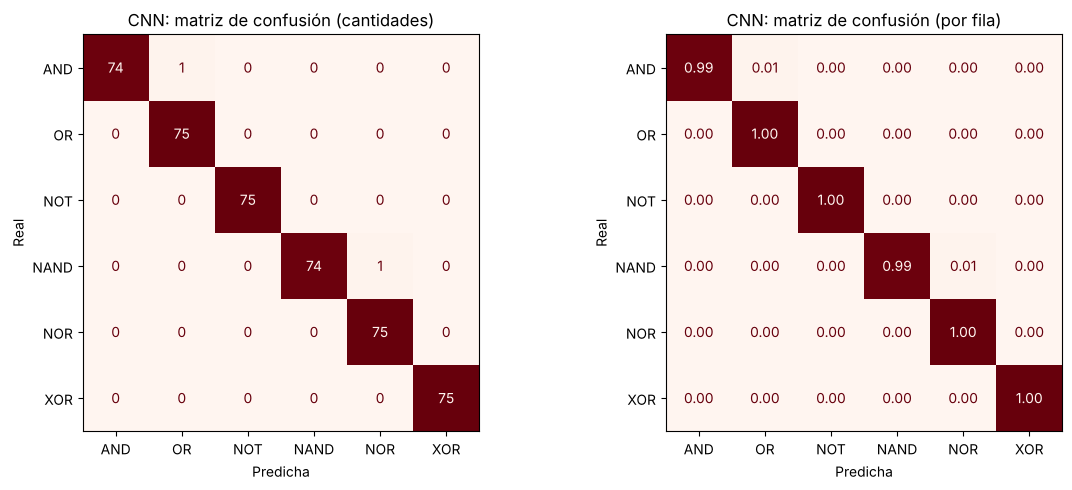

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm = confusion_matrix(y_test, pred_cnn)
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=axes[0], cmap="Reds", colorbar=False)
axes[0].set_title("CNN: matriz de confusión (cantidades)")
cm_norm = confusion_matrix(y_test, pred_cnn, normalize="true")
ConfusionMatrixDisplay(cm_norm, display_labels=CLASES).plot(ax=axes[1], cmap="Reds", colorbar=False, values_format=".2f")
axes[1].set_title("CNN: matriz de confusión (por fila)")
for a in axes:
    a.set_xlabel("Predicha"); a.set_ylabel("Real")
plt.tight_layout(); plt.show()

## 8. Parejas difíciles y análisis de errores

Estas parejas solo se diferencian por un detalle pequeño. Se mide qué porcentaje de los dibujos de una compuerta se confundió con la otra (en ambos sentidos).

In [13]:
PAREJAS = [("AND", "NAND"), ("OR", "NOR"), ("OR", "XOR"), ("NOR", "XOR")]

def confusion_parejas(y_real, y_pred):
    cm = confusion_matrix(y_real, y_pred, labels=range(len(CLASES)))
    filas = []
    for a, b in PAREJAS:
        ia, ib = CLASES.index(a), CLASES.index(b)
        filas.append((f"{a} → {b}", 100 * cm[ia, ib] / max(1, cm[ia].sum())))
        filas.append((f"{b} → {a}", 100 * cm[ib, ia] / max(1, cm[ib].sum())))
    return filas

print(f"{'Confusión':<14}{'MLP':>8}{'CNN':>8}")
for (texto, p_mlp), (_, p_cnn) in zip(confusion_parejas(y_test, pred_mlp), confusion_parejas(y_test, pred_cnn)):
    print(f"{texto:<14}{p_mlp:>7.1f}%{p_cnn:>7.1f}%")

Confusión          MLP     CNN
AND → NAND        0.0%    0.0%
NAND → AND        1.3%    0.0%
OR → NOR          0.0%    0.0%
NOR → OR          0.0%    0.0%
OR → XOR          4.0%    0.0%
XOR → OR          0.0%    0.0%
NOR → XOR         0.0%    0.0%
XOR → NOR         0.0%    0.0%


### Dibujos que la CNN clasificó mal

2 errores de 450 dibujos de prueba


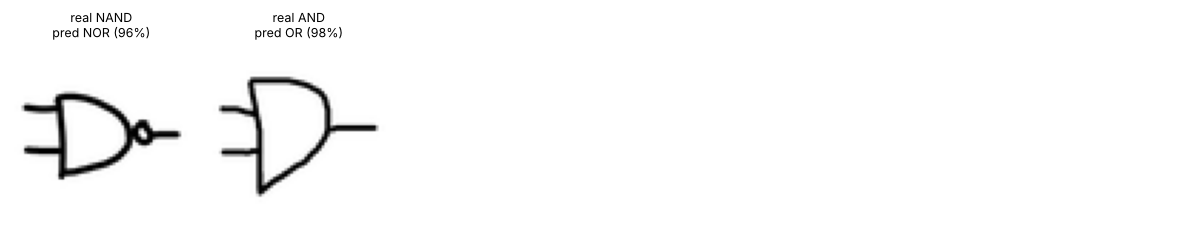

In [14]:
errores = np.where(pred_cnn != y_test)[0]
print(f"{len(errores)} errores de {len(y_test)} dibujos de prueba")
n = min(18, len(errores))
if n:
    cols = 6; filas = int(np.ceil(n / cols))
    fig, axes = plt.subplots(filas, cols, figsize=(12, 2.3 * filas), squeeze=False)
    for k, a in enumerate(axes.flat):
        a.axis("off")
        if k < n:
            i = errores[k]
            a.imshow(X_test[i, ..., 0], cmap="gray_r")
            a.set_title(f"real {CLASES[y_test[i]]}\npred {CLASES[pred_cnn[i]]} ({prob_cnn[i].max():.0%})", fontsize=9)
    plt.tight_layout(); plt.show()

### Comparación MLP contra CNN

In [15]:
resumen = []
for nombre, modelo, pred in [("MLP", mlp, pred_mlp), ("CNN", cnn, pred_cnn)]:
    resumen.append((nombre, accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro"), modelo.count_params()))
print(f"{'Modelo':<8}{'Accuracy':>10}{'F1 macro':>10}{'Parámetros':>13}")
for nombre, acc, f1, params in resumen:
    print(f"{nombre:<8}{acc:>10.3f}{f1:>10.3f}{params:>13,}")

Modelo    Accuracy  F1 macro   Parámetros
MLP          0.987     0.987    1,082,502
CNN          0.996     0.996    1,188,326


## 9. Experimento: ¿cuánto importa la resolución?

MNIST usa imágenes de 28×28. ¿Alcanza esa resolución para ver el círculo de NAND y NOR? Se entrena la **misma CNN** con la **misma división de datos** a 16×16, 28×28 y 64×64, y se compara el resultado.

Hipótesis: a baja resolución el círculo se reduce a uno o dos píxeles, así que deberían aumentar las confusiones AND↔NAND y OR↔NOR.

In [16]:
RESOLUCIONES = [16, 28, 64]
resultados_res = {}
for tam in RESOLUCIONES:
    keras.utils.set_random_seed(SEMILLA)
    Xr_train, Xr_val, Xr_test = separar(a_matriz(recortes, tam))
    modelo = crear_cnn(tam)
    modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    modelo.fit(Xr_train, y_train, validation_data=(Xr_val, y_val), epochs=EPOCAS,
               batch_size=64, callbacks=callbacks(), verbose=0)
    pred = modelo.predict(Xr_test, verbose=0).argmax(axis=1)
    parejas = dict(confusion_parejas(y_test, pred))
    resultados_res[tam] = {
        "accuracy": accuracy_score(y_test, pred),
        "f1": f1_score(y_test, pred, average="macro"),
        "and_nand": (parejas["AND → NAND"] + parejas["NAND → AND"]) / 2,
        "or_nor": (parejas["OR → NOR"] + parejas["NOR → OR"]) / 2,
        "ejemplo": Xr_test[np.where(y_test == CLASES.index("NAND"))[0][0], ..., 0],
    }
    print(f"{tam}×{tam}: accuracy {resultados_res[tam]['accuracy']:.3f}")

16×16: accuracy 0.987


28×28: accuracy 0.991


64×64: accuracy 0.996


Resolución    Accuracy  F1 macro   AND↔NAND   OR↔NOR
16×16            0.987     0.987       0.0%     0.0%
28×28            0.991     0.991       0.0%     0.0%
64×64            0.996     0.996       0.0%     0.0%


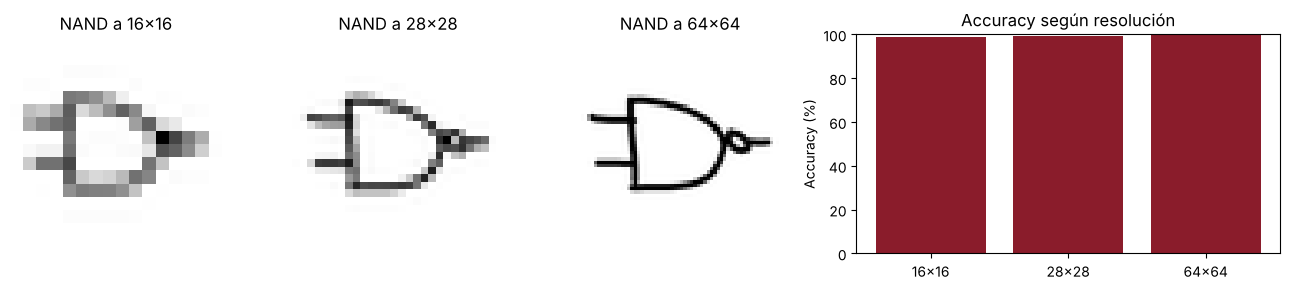

In [17]:
print(f"{'Resolución':<12}{'Accuracy':>10}{'F1 macro':>10}{'AND↔NAND':>11}{'OR↔NOR':>9}")
for tam, r in resultados_res.items():
    print(f"{f'{tam}×{tam}':<12}{r['accuracy']:>10.3f}{r['f1']:>10.3f}{r['and_nand']:>10.1f}%{r['or_nor']:>8.1f}%")

fig, axes = plt.subplots(1, len(RESOLUCIONES) + 1, figsize=(13, 3), gridspec_kw={"width_ratios": [1] * len(RESOLUCIONES) + [2]})
for a, tam in zip(axes, RESOLUCIONES):
    a.imshow(resultados_res[tam]["ejemplo"], cmap="gray_r"); a.set_title(f"NAND a {tam}×{tam}"); a.axis("off")
axes[-1].bar([f"{t}×{t}" for t in RESOLUCIONES], [100 * resultados_res[t]["accuracy"] for t in RESOLUCIONES], color="#8a1c2b")
axes[-1].set_ylabel("Accuracy (%)"); axes[-1].set_ylim(0, 100); axes[-1].set_title("Accuracy según resolución")
plt.tight_layout(); plt.show()

## 10. Generalización a personas nuevas

En la división anterior, los dibujos de una misma persona aparecen tanto en entrenamiento como en prueba, así que la red puede aprender el estilo de cada uno. Una prueba más exigente es **dejar fuera a una persona completa**: entrenar con las demás y evaluar solo con sus dibujos. Se repite para cada persona (validación cruzada por grupos).

Se necesitan al menos 3 personas con nombre. Los dibujos marcados como `anonimo` se usan solo para entrenar.

In [18]:
personas = [a for a, n in collections.Counter(autores).most_common() if a != "anonimo" and n >= 30]
if len(personas) < 3:
    print("Se necesitan al menos 3 personas con 30 dibujos o más. Personas encontradas:", personas)
else:
    resultados_personas = {}
    errores_personas = collections.Counter()
    for persona in personas:
        keras.utils.set_random_seed(SEMILLA)
        prueba = autores == persona
        idx_resto = np.where(~prueba)[0]
        idx_tr, idx_va = train_test_split(idx_resto, test_size=0.15, stratify=y[idx_resto], random_state=SEMILLA)
        modelo = crear_cnn(TAM)
        modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        modelo.fit(X[idx_tr, ..., None], y[idx_tr], validation_data=(X[idx_va, ..., None], y[idx_va]),
                   epochs=EPOCAS, batch_size=64, callbacks=callbacks(), verbose=0)
        pred = modelo.predict(X[prueba, ..., None], verbose=0).argmax(axis=1)
        resultados_personas[persona] = (accuracy_score(y[prueba], pred), int(prueba.sum()))
        errores = collections.Counter((CLASES[r], CLASES[p]) for r, p in zip(y[prueba], pred) if r != p)
        errores_personas.update(errores)
        detalle = ", ".join(f"{r}→{p} ×{n}" for (r, p), n in errores.most_common(3)) or "sin errores"
        print(f"Sin {persona:<12} accuracy en sus {prueba.sum()} dibujos: {resultados_personas[persona][0]:.3f}  ({detalle})")
    media = np.mean([acc for acc, _ in resultados_personas.values()])
    print(f"\nAccuracy promedio con personas no vistas: {media:.3f}")
    print("Confusiones más comunes con personas no vistas:",
          ", ".join(f"{r}→{p} ×{n}" for (r, p), n in errores_personas.most_common(5)) or "ninguna")

Sin faalvial     accuracy en sus 1133 dibujos: 0.986  (OR→AND ×12, NOR→NAND ×4)


Sin christmas    accuracy en sus 873 dibujos: 1.000  (sin errores)


Sin dodo         accuracy en sus 685 dibujos: 1.000  (sin errores)


Sin omar         accuracy en sus 297 dibujos: 1.000  (sin errores)

Accuracy promedio con personas no vistas: 0.996
Confusiones más comunes con personas no vistas: OR→AND ×12, NOR→NAND ×4


## 11. Global Average Pooling y Class Activation Maps (CAM)

En la CNN de la sección 6, el 88% de los parámetros está en una sola capa: la densa de 128 neuronas que recibe los 8×8×128 = 8192 valores aplanados. **Global Average Pooling (GAP)**, visto en la clase de ResNet, reemplaza ese aplanado: promedia cada uno de los 128 mapas de la última convolución y deja un solo número por mapa. Esos 128 promedios van directo a la capa de salida.

Además de reducir parámetros, GAP permite ver **dónde mira la red**. Como cada clase es una suma ponderada de los 128 promedios, se puede hacer la misma suma ponderada con los mapas completos (antes de promediar). El resultado es el **Class Activation Map** de esa clase: un mapa de calor que marca las zonas del dibujo que más empujaron hacia esa respuesta ([Zhou et al., 2016](https://arxiv.org/abs/1512.04150)).

Se entrena una CNN igual a la de la sección 6 con dos cambios: se quita el último max pooling (para que el mapa de calor sea de 16×16 y no de 8×8) y se cambia `Flatten` + `Dense(128)` por `GlobalAveragePooling2D`. Misma división de datos, mismo aumento de datos y mismas épocas.

In [ ]:
def crear_cnn_gap(tam):
    return keras.Sequential([
        keras.Input((tam, tam, 1)),
        crear_aumento(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu", name="ultima_conv"),
        layers.GlobalAveragePooling2D(),
        layers.Dense(len(CLASES), activation="softmax", name="salida"),
    ], name="CNN_GAP")

keras.utils.set_random_seed(SEMILLA)
cnn_gap = crear_cnn_gap(TAM)
cnn_gap.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn_gap.summary()
hist_gap = cnn_gap.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCAS,
                       batch_size=64, callbacks=callbacks(), verbose=2)

Model: "CNN_GAP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_datos (Sequential)   │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ultima_conv (Conv2D)            │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 139,622 (545.40 KB)

 Trainable params: 139,622 (545.40 KB)

 Non-trainable params: 0 (0.00 B)

...

33/33 - 6s - 174ms/step - accuracy: 0.9929 - loss: 0.0215 - val_accuracy: 0.9733 - val_loss: 0.0784 - learning_rate: 5.0000e-04


Epoch 36/60


33/33 - 5s - 155ms/step - accuracy: 0.9957 - loss: 0.0179 - val_accuracy: 0.9933 - val_loss: 0.0349 - learning_rate: 5.0000e-04


Epoch 37/60


33/33 - 5s - 152ms/step - accuracy: 0.9924 - loss: 0.0244 - val_accuracy: 0.9689 - val_loss: 0.1096 - learning_rate: 5.0000e-04


In [ ]:
pred_gap, prob_gap = evaluar(cnn_gap, X_test, y_test)
print(classification_report(y_test, pred_gap, target_names=CLASES, digits=3))

print(f"{'Modelo':<10}{'Accuracy':>10}{'F1 macro':>10}{'Errores':>9}{'Parámetros':>13}")
for nombre, modelo, pred in [("CNN", cnn, pred_cnn), ("CNN + GAP", cnn_gap, pred_gap)]:
    print(f"{nombre:<10}{accuracy_score(y_test, pred):>10.3f}{f1_score(y_test, pred, average='macro'):>10.3f}"
          f"{int((pred != y_test).sum()):>9}{modelo.count_params():>13,}")

              precision    recall  f1-score   support

         AND      1.000     1.000     1.000        75
          OR      0.974     1.000     0.987        75
         NOT      0.974     1.000     0.987        75
        NAND      0.962     1.000     0.980        75
         NOR      1.000     0.920     0.958        75
         XOR      1.000     0.987     0.993        75

    accuracy                          0.984       450
   macro avg      0.985     0.984     0.984       450
weighted avg      0.985     0.984     0.984       450

Modelo      Accuracy  F1 macro  Errores   Parámetros
CNN            0.996     0.996        2    1,188,326
CNN + GAP      0.984     0.984        7      139,622


### Cómo se calcula el CAM

Para un dibujo y una clase *c*:

1. Se obtienen los 128 mapas de la última convolución (16×16 cada uno).
2. Cada mapa se multiplica por el peso que la capa de salida le da a la clase *c* y se suman: `CAM = Σ_k w[k, c] · mapa_k`.
3. Se dejan solo los valores positivos, se escala de 0 a 1 y se agranda a 64×64 para ponerlo encima del dibujo.

Zonas claras = partes del dibujo que más aportaron a la clase predicha.

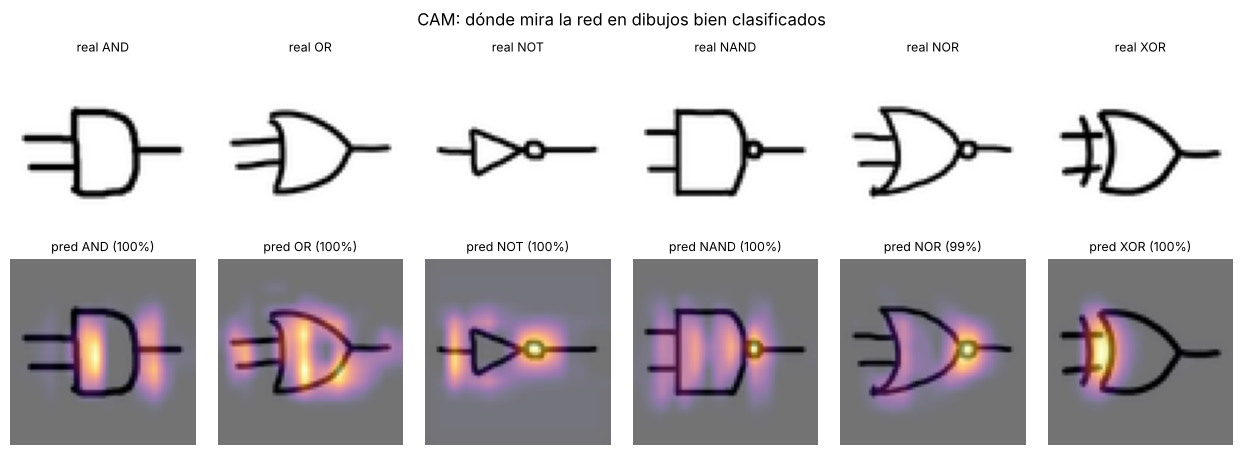

In [ ]:
from PIL import Image as ImagenPIL

# Modelo que devuelve los mapas de la última convolución y las probabilidades.
# Se arma pasando una entrada por las capas entrenadas, sin el aumento de datos.
entrada = keras.Input((TAM, TAM, 1))
x = entrada
for capa in cnn_gap.layers[1:]:
    x = capa(x)
    if capa.name == "ultima_conv":
        mapas_conv = x
extractor = keras.Model(entrada, [mapas_conv, x])
pesos_salida = cnn_gap.get_layer("salida").get_weights()[0]   # (128, 6)

def mapa_cam(imagen, clase=None):
    mapas, prob = extractor.predict(imagen[None], verbose=0)
    clase = int(prob[0].argmax()) if clase is None else clase
    cam = np.maximum(mapas[0] @ pesos_salida[:, clase], 0)
    cam = cam / (cam.max() + 1e-8)
    cam = np.asarray(ImagenPIL.fromarray(cam.astype(np.float32)).resize((TAM, TAM), ImagenPIL.Resampling.BILINEAR))
    return cam, clase, prob[0]

def mostrar_cams(indices, titulo):
    cols = len(indices)
    fig, axes = plt.subplots(2, cols, figsize=(2.1 * cols, 4.6), squeeze=False)
    for k, i in enumerate(indices):
        cam, clase, prob = mapa_cam(X_test[i])
        axes[0, k].imshow(X_test[i, ..., 0], cmap="gray_r")
        axes[0, k].set_title(f"real {CLASES[y_test[i]]}", fontsize=9)
        axes[1, k].imshow(X_test[i, ..., 0], cmap="gray_r")
        axes[1, k].imshow(cam, cmap="inferno", alpha=0.55)
        axes[1, k].set_title(f"pred {CLASES[clase]} ({prob[clase]:.0%})", fontsize=9)
        for a in axes[:, k]:
            a.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout(); plt.show()

# Un dibujo bien clasificado de cada compuerta
rng = np.random.default_rng(1)
ejemplos = [rng.choice(np.where((y_test == c) & (pred_gap == y_test))[0]) for c in range(len(CLASES))]
mostrar_cams(ejemplos, "CAM: dónde mira la red en dibujos bien clasificados")

Los dibujos que falló alguno de los dos modelos (la CNN de la sección 6 o la CNN con GAP). El CAM muestra en qué se fijó la red con GAP al decidir.

9 dibujos fallados por alguno de los dos modelos
  dibujo 14: real NOR, CNN dijo NOR, CNN + GAP dijo NAND
  dibujo 28: real NAND, CNN dijo NOR, CNN + GAP dijo NAND
  dibujo 75: real NOR, CNN dijo NOR, CNN + GAP dijo NOT
  dibujo 124: real NOR, CNN dijo NOR, CNN + GAP dijo NAND
  dibujo 285: real NOR, CNN dijo NOR, CNN + GAP dijo NOT
  dibujo 291: real NOR, CNN dijo NOR, CNN + GAP dijo OR
  dibujo 333: real NOR, CNN dijo NOR, CNN + GAP dijo NAND
  dibujo 368: real XOR, CNN dijo XOR, CNN + GAP dijo OR
  dibujo 431: real AND, CNN dijo OR, CNN + GAP dijo AND


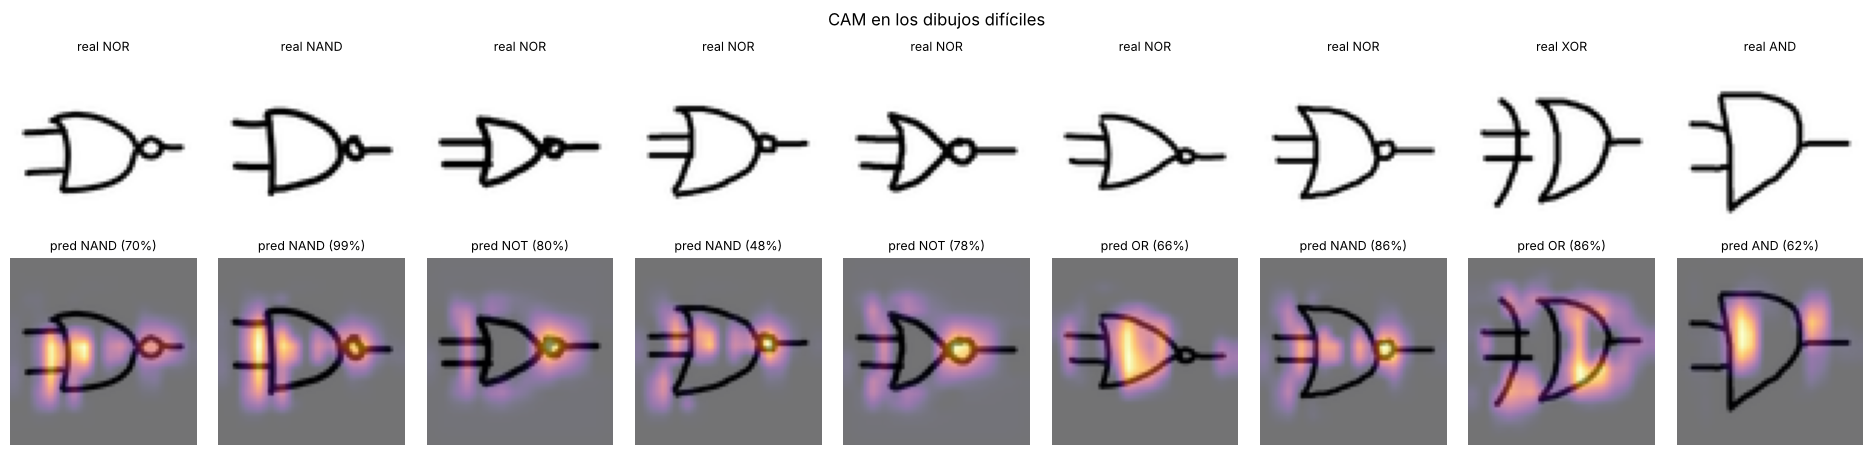

In [ ]:
fallados = np.where((pred_cnn != y_test) | (pred_gap != y_test))[0]
print(f"{len(fallados)} dibujos fallados por alguno de los dos modelos")
for i in fallados:
    print(f"  dibujo {i}: real {CLASES[y_test[i]]}, CNN dijo {CLASES[pred_cnn[i]]}, CNN + GAP dijo {CLASES[pred_gap[i]]}")
if len(fallados):
    mostrar_cams(list(fallados[:10]), "CAM en los dibujos difíciles")

**Lectura de los mapas:**

- En los dibujos bien clasificados, la red mira justo lo que distingue a cada compuerta: la parte trasera recta del AND, la trasera curva del OR, la burbuja de NOT, NAND y NOR, y la curva extra del XOR.
- 6 de los 7 errores de la CNN con GAP son NOR. En unos la red se fija solo en la burbuja y dice NOT o NAND; en otros, la burbuja es pequeña, la ignora y dice OR. En el XOR fallado mira el frente y no la curva extra.
- **Por qué GAP pierde precisión aquí (inferido de los mapas):** al promediar cada mapa sobre toda la imagen, la red sabe *qué* formas aparecen pero no *dónde* están unas respecto de otras. La CNN de la sección 6 conserva esa posición en `Flatten` + `Dense`, a cambio de 8.5 veces más parámetros.

## Guardar el modelo

In [19]:
cnn.save("modelo_compuertas.keras")
with open("clases.json", "w") as f:
    json.dump(CLASES, f)
print("Guardado modelo_compuertas.keras y clases.json")

Guardado modelo_compuertas.keras y clases.json


### Exportar los pesos para la app ("Adivina tu dibujo")

La app no usa TensorFlow, porque ocupa más de 1 GB y el plan gratuito de PythonAnywhere da 512 MB. Pero una red ya entrenada solo hace multiplicaciones con sus pesos, así que la app repite las mismas capas con numpy (archivo `prediccion.py`). Para eso basta guardar los pesos de las capas de convolución y densas en `pesos_cnn.npz`. El aumento de datos y el dropout no tienen pesos: solo actúan durante el entrenamiento.

Después se copia `pesos_cnn.npz` al repositorio, junto a `main.py`, y en PythonAnywhere se hace `git pull` y **Reload**. Si se cambia la arquitectura de la CNN, hay que cambiar también la función `predecir` de `prediccion.py`.

In [20]:
pesos = [w for capa in cnn.layers if isinstance(capa, (layers.Conv2D, layers.Dense)) for w in capa.get_weights()]
np.savez("pesos_cnn.npz", *pesos)
print(f"Guardado pesos_cnn.npz: {len(pesos)} arreglos, {sum(w.size for w in pesos):,} pesos")

try:
    from google.colab import files
    files.download("pesos_cnn.npz")
except ImportError:
    pass

Guardado pesos_cnn.npz: 14 arreglos, 1,188,326 pesos


## Resumen de resultados

Esta celda imprime los números clave para copiarlos en las conclusiones y en la exposición.

In [21]:
acc_mlp, f1_mlp = resumen[0][1], resumen[0][2]
acc_cnn, f1_cnn = resumen[1][1], resumen[1][2]
print(f"Dataset: {len(y)} dibujos, {len(set(autores))} personas")
print(f"MLP: accuracy {acc_mlp:.1%}, F1 macro {f1_mlp:.3f}")
print(f"CNN: accuracy {acc_cnn:.1%}, F1 macro {f1_cnn:.3f}")
f1_clases = f1_score(y_test, pred_cnn, average=None)
peores = [CLASES[i] for i in np.where(np.isclose(f1_clases, f1_clases.min()))[0]]
if len(peores) == len(CLASES):
    print(f"Clase más difícil para la CNN: ninguna, todas con F1 {f1_clases.min():.3f} en prueba")
else:
    print(f"Clases con menor F1 en la CNN: {', '.join(peores)} (F1 {f1_clases.min():.3f})")
for tam, r in resultados_res.items():
    print(f"CNN a {tam}×{tam}: accuracy {r['accuracy']:.1%}, confusión AND↔NAND {r['and_nand']:.1f}%, OR↔NOR {r['or_nor']:.1f}%")
if "resultados_personas" in globals():
    print(f"CNN con personas no vistas: accuracy promedio {media:.1%}")
    print("Confusiones más comunes con personas no vistas:",
          ", ".join(f"{r}→{p} ×{n}" for (r, p), n in errores_personas.most_common(3)) or "ninguna")

Dataset: 3000 dibujos, 5 personas
MLP: accuracy 98.7%, F1 macro 0.987
CNN: accuracy 99.6%, F1 macro 0.996
Clases con menor F1 en la CNN: AND, NAND (F1 0.993)
CNN a 16×16: accuracy 98.7%, confusión AND↔NAND 0.0%, OR↔NOR 0.0%
CNN a 28×28: accuracy 99.1%, confusión AND↔NAND 0.0%, OR↔NOR 0.0%
CNN a 64×64: accuracy 99.6%, confusión AND↔NAND 0.0%, OR↔NOR 0.0%
CNN con personas no vistas: accuracy promedio 99.6%
Confusiones más comunes con personas no vistas: OR→AND ×12, NOR→NAND ×4


## 12. Conclusiones

1. **CNN contra MLP:** la CNN obtuvo 99.6% de accuracy (2 errores en 450 dibujos de prueba) frente a 98.7% del MLP (6 errores). La diferencia es pequeña porque, después del recorte y el centrado, los dibujos se parecen mucho entre sí. Aun así la CNN comete tres veces menos errores: las convoluciones reconocen formas locales (rectas, curvas, círculos) aunque no estén exactamente en el mismo lugar, mientras que el MLP ve píxeles sueltos.
2. **Parejas difíciles:** la CNN no confundió ninguna de las parejas que solo se diferencian por la burbuja (AND/NAND y OR/NOR). Sus dos errores fueron un AND leído como OR y un NAND leído como NOR, en dibujos con la parte trasera inclinada o la base curva, que es justamente lo que separa la familia AND de la familia OR. El MLP sí confundió OR → XOR (4.0%) y NAND → AND (1.3%).
3. **Resolución:** la accuracy sube con la resolución: 98.7% a 16×16, 99.1% a 28×28 y 99.6% a 64×64. La mejora es pequeña porque incluso a 16×16 la burbuja de NAND y NOR sobrevive como una mancha oscura en la salida: ninguna resolución confundió AND↔NAND ni OR↔NOR.
4. **Personas nuevas:** entrenando sin una persona y probando con sus dibujos, la accuracy promedio fue 99.6%. Tres personas obtuvieron 100%. Sin faalvial bajó a 98.6%, sobre todo por OR → AND (12) y NOR → NAND (4); por lo que se ve en sus dibujos, faalvial hace la parte trasera del OR casi recta y el frente redondeado, un estilo que los demás no usan. El estilo personal influye, y más personas aportando datos mejorarían la generalización.
5. **Calidad de los datos:** antes de entrenar se revisaron los 3000 dibujos con modelos de validación cruzada. 9 (0.3%) estaban mal hechos (incompletos, con la forma de otra compuerta o con un punto suelto que desplaza el recorte) y se reemplazaron por dibujos nuevos.
6. **GAP y CAM:** cambiar `Flatten` + `Dense(128)` por Global Average Pooling redujo los parámetros de 1 188 326 a 139 622 (8.5 veces menos), pero la accuracy bajó de 99.6% a 98.4% (7 errores, 6 de ellos en NOR). Los mapas CAM muestran que la red mira lo que distingue a cada compuerta: la trasera recta del AND, la curva del OR, la burbuja y la curva extra del XOR. En los errores, en cambio, se queda con una sola pista (por ejemplo, solo la burbuja). Al promediar, GAP sabe qué formas hay pero no dónde están unas respecto de otras, y en este problema esa posición importa.
7. **Limitaciones y trabajo futuro:** los datos vienen de solo 4 personas, y la división aleatoria pone dibujos de las mismas personas en entrenamiento y prueba; por eso la prueba con personas nuevas es la más exigente. Además, el sistema clasifica compuertas sueltas: para digitalizar un circuito completo haría falta detectar y separar cada compuerta y sus conexiones (detección de objetos).